In [ ]:
"""
Correlations between number of orthogroups, number of genes, genome span, & GC content

~ and getting the true number of single-copy genes

07/09/2026
Amjad Khalaf

"""

In [ ]:

### First generate a dataframe, where each row is genome, order, span, number of genes, GC content

In [ ]:
### load up orthogroups the same way I did with the upsetplot

OrthogroupScores = {}
scoreFile = "orthogroup_TE_scores.txt" # same score file we generated for Fig 3
with open(scoreFile) as file:
    for line in file:
        line = line.rstrip("\n")
        fields = line.split("\t")
        orthogroup = fields[0]
        score = float(fields[1])
        OrthogroupScores[orthogroup] = score

import pandas as pd
orthogroupsTSV = "Orthogroups.GeneCount.tsv"
df = pd.read_csv(orthogroupsTSV, sep='\t')

geneCountDict = {} #Key is species, values is gene (or protein) number
orthogroupDict = {} #Key is species, values is list of orthogroups
speciesList = []
with open(orthogroupsTSV) as file:
    for line in file:
        line = line.rstrip("\n")
        fields = line.split("\t")
        if fields[0] == "Orthogroup":
            speciesList = fields.copy()
        else:
            for i, field in enumerate(fields):
                if field.startswith("OG"):
                    orthogroup = field
                else:
                    if int(field) > 0:
                        # retrieve position of field in list to find out what species it is
                        species = speciesList[i]
                        if species in orthogroupDict.keys() and OrthogroupScores[orthogroup] < 1:
                            orthogroupDict[species].append(orthogroup)
                            geneCountDict[species] = geneCountDict[species] + int(field)
                        else:
                            if OrthogroupScores[orthogroup] < 1:
                                orthogroupDict[species] = [orthogroup]
                                geneCountDict[species] = int(field)

In [ ]:
### setting up dataframe
# the species list files are the same as the ones used in Fig 3
# a lot of the operations here are to do with dealing with the names of genome assemblies, which were all housed under "final_genomes" when I ran this

from collections import defaultdict
from Bio import SeqIO
import glob

df = pd.DataFrame(columns=['Genome', 'Order', 'Orthogroup_number', 'Protein_number', 'Genome_span', 'GC_content'])

Ovavesiculida_file = "ovavesiculida_species_list.txt"
with open(Ovavesiculida_file) as f:
    for line in f:
        line = line.rstrip("\n")
        if line == "cjLepRept2":
            pass
        else:
            orthogroup_number = len(orthogroupDict[line])
            if "GCA_" in line:
                pattern = "final_genomes/*" + line.split("_")[-2] + "_" + line.split("_")[-1] + "*.fa"
                fastaFile = glob.glob(pattern)[0]
            else:
                fastaFile = "final_genomes/" + line + ".fa"
            span = sum(len(record) for record in SeqIO.parse(fastaFile, "fasta"))
            gcCount = 0
            for record in SeqIO.parse(fastaFile, "fasta"):
                gcCount = gcCount + record.seq.count("C") + record.seq.count("G") + record.seq.count("c") + record.seq.count("g")  
            proteinNumber = geneCountDict[line]
            new_row = [{'Genome': line, 'Order': 'Ovavesiculida', 'Orthogroup_number': orthogroup_number, 'Protein_number': proteinNumber, 'Genome_span': span, 'GC_content':gcCount/span}]
            df = pd.concat([df, pd.DataFrame(new_row)], ignore_index=True)

OrphanLineage_file = "astathelohaniida_species_list.txt"
with open(OrphanLineage_file) as f:
    for line in f:
        line = line.rstrip("\n")
        orthogroup_number = len(orthogroupDict[line])
        if "GCA_" in line:
            pattern = "final_genomes/*" + line.split("_")[-2] + "_" + line.split("_")[-1] + "*.fa"
            fastaFile = glob.glob(pattern)[0]
        else:
            fastaFile = "final_genomes/" + line + ".fa"

        span = sum(len(record) for record in SeqIO.parse(fastaFile, "fasta"))
        gcCount = 0
        for record in SeqIO.parse(fastaFile, "fasta"):
            gcCount = gcCount + record.seq.count("C") + record.seq.count("G") + record.seq.count("c") + record.seq.count("g")  
        proteinNumber = geneCountDict[line]
        new_row = [{'Genome': line, 'Order': 'Astathelohaniida', 'Orthogroup_number': orthogroup_number, 'Protein_number': proteinNumber, 'Genome_span': span, 'GC_content':gcCount/span}]
        df = pd.concat([df, pd.DataFrame(new_row)], ignore_index=True)


Amblyosporida_file = "amblyosporida_species_list.txt"
with open(Amblyosporida_file) as f:
    for line in f:
        line = line.rstrip("\n")
        if line == "idAnoSqua2_b" or line == "ilAceEphe1_GCA_986199865.1" or line =="idMegDoli1_GCA_985805875.1" or line == "idLucSpea1_GCA_985809255.1":
            pass
        else:
            orthogroup_number = len(orthogroupDict[line])
            if "GCA_" in line:
                pattern = "final_genomes/*" + line.split("_")[-2] + "_" + line.split("_")[-1] + "*.fa"
                fastaFile = glob.glob(pattern)[0]
            else:
                fastaFile = "final_genomes/" + line + ".fa"

            span = sum(len(record) for record in SeqIO.parse(fastaFile, "fasta"))
            gcCount = 0
            for record in SeqIO.parse(fastaFile, "fasta"):
                gcCount = gcCount + record.seq.count("C") + record.seq.count("G") + record.seq.count("c") + record.seq.count("g")  
            proteinNumber = geneCountDict[line]
            new_row = [{'Genome': line, 'Order': 'Amblyosporida', 'Orthogroup_number': orthogroup_number, 'Protein_number': proteinNumber, 'Genome_span': span, 'GC_content':gcCount/span}]
            df = pd.concat([df, pd.DataFrame(new_row)], ignore_index=True)


Glugeida_file = "glugeida_species_list.txt"
with open(Glugeida_file) as f:
    for line in f:
        line = line.rstrip("\n")
        if line == "Dictyocoela_roeselum_GCA_016255985.1" or line == "Pseudoloma_neurophilia_GCA_001432165.1" or line == "Cucumispora_dikerogammari_GCA_014805705.1":
            pass
        else:
            orthogroup_number = len(orthogroupDict[line])

            if "GCA_" in line:
                pattern = "final_genomes/*" + line.split("_")[-2] + "_" + line.split("_")[-1] + "*.fa"
                fastaFile = glob.glob(pattern)[0]
            else:
                fastaFile = "final_genomes/" + line + ".fa"

            span = sum(len(record) for record in SeqIO.parse(fastaFile, "fasta"))
            gcCount = 0
            for record in SeqIO.parse(fastaFile, "fasta"):
                gcCount = gcCount + record.seq.count("C") + record.seq.count("G") + record.seq.count("c") + record.seq.count("g")  
            proteinNumber = geneCountDict[line]
            new_row = [{'Genome': line, 'Order': 'Glugeida', 'Orthogroup_number': orthogroup_number, 'Protein_number': proteinNumber, 'Genome_span': span, 'GC_content':gcCount/span}]
            df = pd.concat([df, pd.DataFrame(new_row)], ignore_index=True)


Neopereziida_file = "neopereziida_species_list.txt"
with open(Neopereziida_file) as f:
    for line in f:
        line = line.rstrip("\n")
        if line == "ieEphVulg1_GCA_985806015.1" or line == "idTipConf1_GCA_985805865.1":
            pass
        else:
            orthogroup_number = len(orthogroupDict[line])
            if "GCA_" in line:
                pattern = "final_genomes/*" + line.split("_")[-2] + "_" + line.split("_")[-1] + "*.fa"
                fastaFile = glob.glob(pattern)[0]
            else:
                fastaFile = "final_genomes/" + line + ".fa"


            span = sum(len(record) for record in SeqIO.parse(fastaFile, "fasta"))
            gcCount = 0
            for record in SeqIO.parse(fastaFile, "fasta"):
                gcCount = gcCount + record.seq.count("C") + record.seq.count("G") + record.seq.count("c") + record.seq.count("g")  
            proteinNumber = geneCountDict[line]
            new_row = [{'Genome': line, 'Order': 'Neopereziida', 'Orthogroup_number': orthogroup_number, 'Protein_number': proteinNumber, 'Genome_span': span, 'GC_content':gcCount/span}]
            df = pd.concat([df, pd.DataFrame(new_row)], ignore_index=True)


Nosematida_file = "nosematida_species_list.txt"
with open(Nosematida_file) as f:
    for line in f:
        line = line.rstrip("\n")
        if line == "ilMytImpu1_GCA_986195055.1" or line == "ihCicViri2_GCA_985805755.1" or line == "iyVulBima1_GCA_985801995.1" or line == "Nosema_muscidifuracis_GCA_028335825.1" or line == "iyGorLati1" or line == "ilBlaLact1_GCA_986194925.1" or line == "icChrPopu2" or line == "ilEreLige1_GCA_986264945.1" or line == "ilNocJanh1_GCA_986264975.1" or line == "iyForRufa2_GCA_985801395.1" or line == "Nosema_rusticus_GCA_046563365.1" or line == "iyAmbProt1_GCA_986191025.1" or line == "iySphCras2_GCA_985800635.1" or line == "iyNetVirg2_GCA_985803815.1" or line == "iyChoSubc1_GCA_986194725.1" or line == "ilOchDupl1_GCA_986194575.1":
            pass
        else:
            orthogroup_number = len(orthogroupDict[line])

            if "GCA_" in line:
                pattern = "final_genomes/*" + line.split("_")[-2] + "_" + line.split("_")[-1] + "*.fa"
                fastaFile = glob.glob(pattern)[0]
            else:
                fastaFile = "final_genomes/" + line + ".fa"

            span = sum(len(record) for record in SeqIO.parse(fastaFile, "fasta"))
            gcCount = 0
            for record in SeqIO.parse(fastaFile, "fasta"):
                gcCount = gcCount + record.seq.count("C") + record.seq.count("G") + record.seq.count("c") + record.seq.count("g")  
            proteinNumber = geneCountDict[line]
            new_row = [{'Genome': line, 'Order': 'Nosematida', 'Orthogroup_number': orthogroup_number, 'Protein_number': proteinNumber, 'Genome_span': span, 'GC_content':gcCount/span}]
            df = pd.concat([df, pd.DataFrame(new_row)], ignore_index=True)

Enterocytozoonida_file = "enterocytozoonida_species_list.txt"
with open(Enterocytozoonida_file) as f:
    for line in f:
        line = line.rstrip("\n")
        if line == "icHarAnxi1" or line == "Agmasoma_sp_GCA_029232285.1" or line == "Hepatospora_eriocheir_GCA_002087885.1" or line == "Enterocytozoon_hepatopenaei_GCA_026692725.1" or line == "Enterospora_canceri_GCA_002087915.1" or line == "Enterocytozoon_bieneusi_GCA_000209485.1" or line == "iqTelOcea3_a" or line == "iqTelOcea30" or line == "icAcuMacu1" or line == "ieEcdTorr1" or line == "cbUloPhyl1" or line == "idNeuQuad1_GCA_985805835.1" or line == "icBraCrep1" or line == "idAnoSqua2_a" or line == "idHydMili2_a" or line == "Alternosema_astaquatica_GCA_030386735.1":
            pass
        else:
            orthogroup_number = len(orthogroupDict[line])
            if "GCA_" in line:
                pattern = "final_genomes/*" + line.split("_")[-2] + "_" + line.split("_")[-1] + "*.fa"
                fastaFile = glob.glob(pattern)[0]
            else:
                fastaFile = "final_genomes/" + line + ".fa"


            span = sum(len(record) for record in SeqIO.parse(fastaFile, "fasta"))
            gcCount = 0
            for record in SeqIO.parse(fastaFile, "fasta"):
                gcCount = gcCount + record.seq.count("C") + record.seq.count("G") + record.seq.count("c") + record.seq.count("g")  
            proteinNumber = geneCountDict[line]
            new_row = [{'Genome': line, 'Order': 'Enterocytozoonida', 'Orthogroup_number': orthogroup_number, 'Protein_number': proteinNumber, 'Genome_span': span, 'GC_content':gcCount/span}]
            df = pd.concat([df, pd.DataFrame(new_row)], ignore_index=True)


Mitosporidia = ["Mitosporidium_daphniae_GCA_052576055.1", "qlDicSaun7"]
for line in Mitosporidia:
    orthogroup_number = len(orthogroupDict[line])
    if "GCA_" in line:
        pattern = "final_genomes/*" + line.split("_")[-2] + "_" + line.split("_")[-1] + "*.fa"
        fastaFile = glob.glob(pattern)[0]
    else:
        fastaFile = "final_genomes/" + line + ".fa"
    span = sum(len(record) for record in SeqIO.parse(fastaFile, "fasta"))
    gcCount = 0
    for record in SeqIO.parse(fastaFile, "fasta"):
        gcCount = gcCount + record.seq.count("C") + record.seq.count("G") + record.seq.count("c") + record.seq.count("g")  
    proteinNumber = geneCountDict[line]
    new_row = [{'Genome': line, 'Order': 'Mitosporidia', 'Orthogroup_number': orthogroup_number, 'Protein_number': proteinNumber, 'Genome_span': span, 'GC_content':gcCount/span}]
    df = pd.concat([df, pd.DataFrame(new_row)], ignore_index=True)

Metchnikovellida = ["Metchnikovella_incurvata_GCA_003600395.1", "Amphiamblys_sp._WSBS2006_GCA_001875675.1"]
for line in Metchnikovellida:
    orthogroup_number = len(orthogroupDict[line])
    pattern = "/lustre/scratch126/tol/teams/lawniczak/projects/microsporidia/royalSoc/genome_phylo/final_genomes/*" + line.split("_")[-2] + "_" + line.split("_")[-1] + "*.fa"
    fastaFile = glob.glob(pattern)[0]   
    span = sum(len(record) for record in SeqIO.parse(fastaFile, "fasta"))
    gcCount = 0
    for record in SeqIO.parse(fastaFile, "fasta"):
        gcCount = gcCount + record.seq.count("C") + record.seq.count("G") + record.seq.count("c") + record.seq.count("g")  
    proteinNumber = geneCountDict[line]
    new_row = [{'Genome': line, 'Order': 'Metchnikovellida', 'Orthogroup_number': orthogroup_number, 'Protein_number': proteinNumber, 'Genome_span': span, 'GC_content':gcCount/span}]
    df = pd.concat([df, pd.DataFrame(new_row)], ignore_index=True)


/tmp/ipykernel_447776/4156193754.py:28: FutureWarning: The behavior of DataFrame concatenation with empty or all-NA entries is deprecated. In a future version, this will no longer exclude empty or all-NA columns when determining the result dtypes. To retain the old behavior, exclude the relevant entries before the concat operation.
  df = pd.concat([df, pd.DataFrame(new_row)], ignore_index=True)


In [ ]:
# modelling orthogroup number vs different categories

import statsmodels.formula.api as smf

df['Orthogroup_number'] = pd.to_numeric(df['Orthogroup_number'], errors='coerce')
df['Protein_number'] = pd.to_numeric(df['Protein_number'], errors='coerce')
df['Genome_span'] = pd.to_numeric(df['Genome_span'], errors='coerce')
df['GC_content'] = pd.to_numeric(df['GC_content'], errors='coerce')

for col in ['Protein_number', 'Genome_span', 'GC_content']:
    df[col + '_scaled'] = (df[col] - df[col].mean()) / df[col].std()

scaled_formula = "Orthogroup_number ~ Protein_number_scaled + Genome_span_scaled + GC_content_scaled"
mixed_model = smf.mixedlm(scaled_formula, df, groups=df["Order"])
model_result = mixed_model.fit()

print(model_result.summary())

                 Mixed Linear Model Regression Results
Model:               MixedLM    Dependent Variable:    Orthogroup_number
No. Observations:    74         Method:                REML             
No. Groups:          9          Scale:                 460124.1865      
Min. group size:     2          Log-Likelihood:        -569.6938        
Max. group size:     21         Converged:             Yes              
Mean group size:     8.2                                                
------------------------------------------------------------------------
                        Coef.    Std.Err.   z    P>|z|  [0.025   0.975] 
------------------------------------------------------------------------
Intercept               2594.880  217.116 11.952 0.000 2169.341 3020.419
Protein_number_scaled   1271.133  150.924  8.422 0.000  975.327 1566.939
Genome_span_scaled      -507.722  153.548 -3.307 0.001 -808.671 -206.774
GC_content_scaled        -67.448   93.305 -0.723 0.470 -250.324  115.

In [ ]:
# modelling orthogroup number vs different categories
# but now stratify by order

import pandas as pd
import statsmodels.formula.api as smf

for order_name, group_df in df.groupby('Order'):
    
    # Check if the order has enough genomes to mathematically fit the model
    # (With 3 predictors + 1 intercept, we need at least 5 data points)
    if len(group_df) >= 5:  
        print(f"\n" + "="*60)
        print(f" REGRESSION MODEL FOR ORDER: {order_name.upper()} (N = {len(group_df)})")
        print("="*60)
        
        formula = "Orthogroup_number ~ Protein_number_scaled + Genome_span_scaled + GC_content_scaled"
        
        order_model = smf.ols(formula, data=group_df).fit()
        
        print(f"R-squared: {order_model.rsquared:.3f}")
        print(order_model.summary().tables[1])
        
    else:
        print(f"\nSkipping Order '{order_name}': Only has {len(group_df)} genome(s). "
              f"Need at least 5 genomes to run this model.")


 REGRESSION MODEL FOR ORDER: AMBLYOSPORIDA (N = 7)
R-squared: 0.921
                            coef    std err          t      P>|t|      [0.025      0.975]
-----------------------------------------------------------------------------------------
Intercept              2385.3523    815.136      2.926      0.061    -208.773    4979.477
Protein_number_scaled  2850.5875    671.247      4.247      0.024     714.381    4986.794
Genome_span_scaled     -492.4106    289.113     -1.703      0.187   -1412.498     427.677
GC_content_scaled      1305.9297    780.918      1.672      0.193   -1179.301    3791.161

Skipping Order 'Astathelohaniida': Only has 3 genome(s). Need at least 5 genomes to run this model.

 REGRESSION MODEL FOR ORDER: ENTEROCYTOZOONIDA (N = 20)
R-squared: 0.763
                            coef    std err          t      P>|t|      [0.025      0.975]
-----------------------------------------------------------------------------------------
Intercept              2227.6604    

/software/treeoflife/conda/users/envs/team222/ak37/toytree/lib/python3.11/site-packages/statsmodels/stats/stattools.py:74: ValueWarning: omni_normtest is not valid with less than 8 observations; 7 samples were given.
  warn("omni_normtest is not valid with less than 8 observations; %i "
/software/treeoflife/conda/users/envs/team222/ak37/toytree/lib/python3.11/site-packages/statsmodels/stats/stattools.py:74: ValueWarning: omni_normtest is not valid with less than 8 observations; 5 samples were given.
  warn("omni_normtest is not valid with less than 8 observations; %i "
/software/treeoflife/conda/users/envs/team222/ak37/toytree/lib/python3.11/site-packages/scipy/stats/_axis_nan_policy.py:531: UserWarning: kurtosistest only valid for n>=20 ... continuing anyway, n=10
  res = hypotest_fun_out(*samples, **kwds)


In [ ]:
# R-squared and p values for orthogroup number vs genome span

import pandas as pd
import statsmodels.formula.api as smf

df["Orthogroup_number"] = pd.to_numeric(
    df["Orthogroup_number"], errors="coerce"
)
df["Genome_span"] = pd.to_numeric(df["Genome_span"], errors="coerce")

clean_df = df.dropna(subset=["Orthogroup_number", "Genome_span"])

stats_list = []

for order_name, group in clean_df.groupby("Order"):
    sample_size = len(group)

    if sample_size >= 2:
        model = smf.ols("Orthogroup_number ~ Genome_span", data=group).fit()

        stats_list.append(
            {
                "Order": order_name,
                "R_Squared": round(model.rsquared, 4),
                "P_Value": round(model.pvalues["Genome_span"], 5),
                "Sample_Size": sample_size,
                "Slope": model.params["Genome_span"]
            }
        )
    else:
        # Not enough data points to compute a trend line
        stats_list.append(
            {
                "Order": order_name,
                "R_Squared": None,
                "P_Value": None,
                "Sample_Size": sample_size,
                "Slope": model.params["Genome_span"]
            }
        )

results_df = pd.DataFrame(stats_list)
print(results_df)


               Order  R_Squared  P_Value  Sample_Size     Slope
0      Amblyosporida     0.0054  0.87590            7 -0.000009
1   Astathelohaniida     0.9438  0.15240            3  0.000429
2  Enterocytozoonida     0.7384  0.00000           20  0.000204
3           Glugeida     0.4242  0.23381            5  0.000040
4   Metchnikovellida     1.0000      NaN            2 -0.000596
5       Mitosporidia     1.0000      NaN            2  0.007623
6       Neopereziida     0.8060  0.10220            4  0.000436
7         Nosematida     0.6235  0.00002           21  0.000102
8      Ovavesiculida     0.3059  0.09727           10  0.000273


In [ ]:
# R-squared and p values for orthogroup number vs GC content

import pandas as pd
import statsmodels.formula.api as smf

df["Orthogroup_number"] = pd.to_numeric(
    df["Orthogroup_number"], errors="coerce"
)
df["GC_content"] = pd.to_numeric(df["GC_content"], errors="coerce")

clean_df = df.dropna(subset=["Orthogroup_number", "GC_content"])

stats_list = []

for order_name, group in clean_df.groupby("Order"):
    sample_size = len(group)

    if sample_size >= 2:
        model = smf.ols("Orthogroup_number ~ GC_content", data=group).fit()

        stats_list.append(
            {
                "Order": order_name,
                "R_Squared": round(model.rsquared, 4),
                "P_Value": round(model.pvalues["GC_content"], 5),
                "Sample_Size": sample_size,
                "Slope": model.params["GC_content"]
            }
        )
    else:
        stats_list.append(
            {
                "Order": order_name,
                "R_Squared": None,
                "P_Value": None,
                "Sample_Size": sample_size,

            }
        )

results_df = pd.DataFrame(stats_list)
print(results_df)

               Order  R_Squared  P_Value  Sample_Size          Slope
0      Amblyosporida     0.3438  0.16644            7   22442.432480
1   Astathelohaniida     0.2425  0.67217            3 -229118.399177
2  Enterocytozoonida     0.2442  0.02679           20   -3343.554547
3           Glugeida     0.0000  0.99409            5     -61.349481
4   Metchnikovellida     1.0000      NaN            2     732.670390
5       Mitosporidia     1.0000      NaN            2   35649.087356
6       Neopereziida     0.4846  0.30387            4  -10950.790623
7         Nosematida     0.0992  0.16444           21   -1728.775677
8      Ovavesiculida     0.4304  0.03941           10   -2971.696325


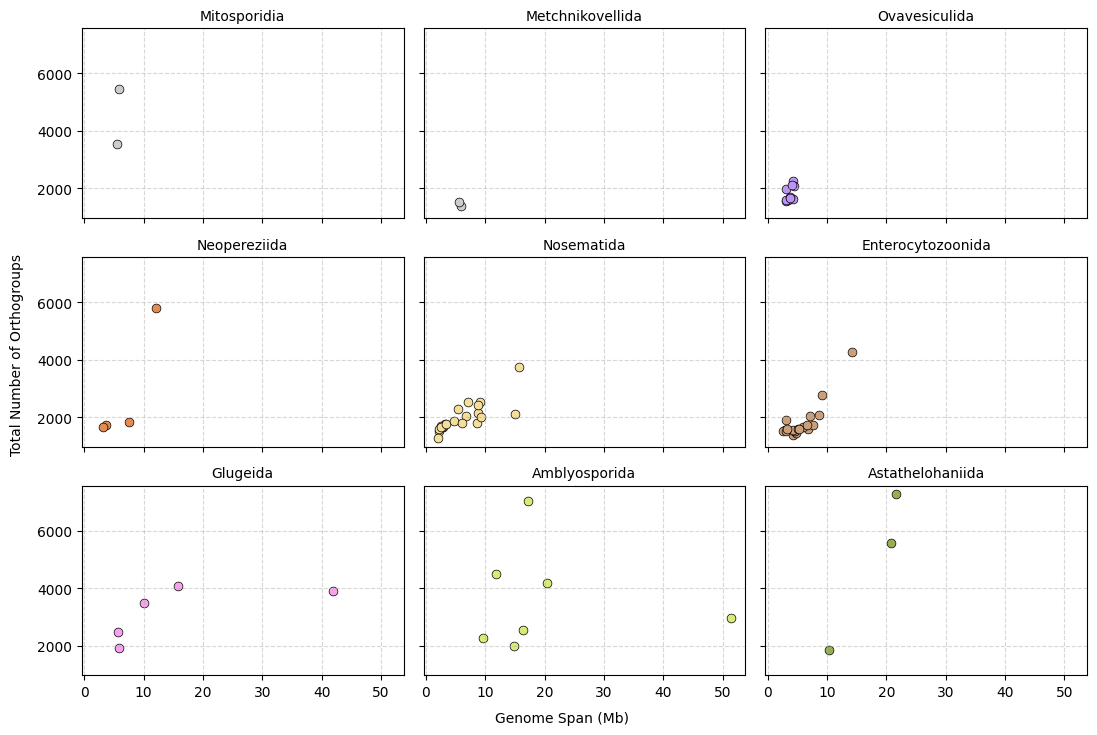

In [ ]:
# plot the genome span panel!

import matplotlib.pyplot as plt
plt.rcParams['svg.fonttype'] = 'none'

fig, axs = plt.subplots(3, 3, sharey=True, sharex=True)
fig.set_figheight(8)
fig.set_figwidth(12)

fig.text(0.5, 0.04, "Genome Span (Mb)", ha="center")
fig.text(
    0.04,
    0.5,
    "Total Number of Orthogroups",
    va="center",
    rotation="vertical",
)

orderNames = [
    "Mitosporidia",
    "Metchnikovellida",
    "Ovavesiculida",
    "Neopereziida",
    "Nosematida",
    "Enterocytozoonida",
    "Glugeida",
    "Amblyosporida",
    "Astathelohaniida",
]
position = {order: idx for idx, order in enumerate(orderNames)}
colors = [
    "#ccccccff",
    "#ccccccff",
    "#bc94f7ff",
    "#e48b50ff",
    "#f5dd9aff",
    "#cb9f7aff",
    "#faa0ecff",
    "#d6ec78ff",
    "#95ae52ff",
]

axs_flat = axs.flatten()

for i, order_name in enumerate(orderNames):
    pos = position[order_name]
    ax = axs_flat[pos]

    group = df[df["Order"] == order_name]

    if group.empty:
        ax.set_title(order_name, fontsize=10)
        ax.grid(True, linestyle="--", alpha=0.5)
        continue

    genomeSpans = group["Genome_span"] / 1000000
    numOfUniqueOrthogroups = group["Orthogroup_number"]

    ax.scatter(
        genomeSpans,
        numOfUniqueOrthogroups,
        color=colors[i],
        alpha=1,
        linewidths=0.5,
        edgecolors="black",
        s=40,  # Explicit dot size
    )

    ax.set_title(order_name, fontsize=10)
    ax.grid(True, linestyle="--", alpha=0.5)

plt.tight_layout(rect=[0.05, 0.05, 0.95, 0.95])
plt.savefig("correlations_A.svg")
plt.show()


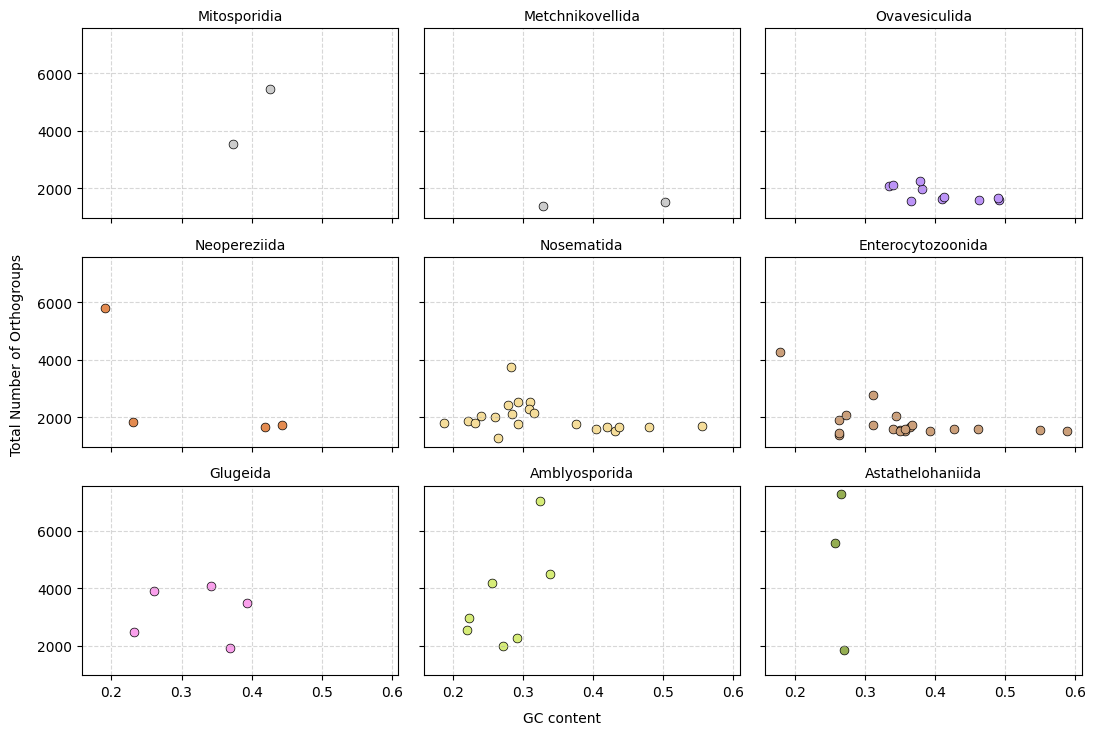

In [ ]:
# plot the GC content panel

import matplotlib.pyplot as plt
plt.rcParams['svg.fonttype'] = 'none'

fig, axs = plt.subplots(3, 3, sharey=True, sharex=True)
fig.set_figheight(8)
fig.set_figwidth(12)

fig.text(0.5, 0.04, "GC content", ha="center")
fig.text(
    0.04,
    0.5,
    "Total Number of Orthogroups",
    va="center",
    rotation="vertical",
)

orderNames = [
    "Mitosporidia",
    "Metchnikovellida",
    "Ovavesiculida",
    "Neopereziida",
    "Nosematida",
    "Enterocytozoonida",
    "Glugeida",
    "Amblyosporida",
    "Astathelohaniida",
]
position = {order: idx for idx, order in enumerate(orderNames)}
colors = [
    "#ccccccff",
    "#ccccccff",
    "#bc94f7ff",
    "#e48b50ff",
    "#f5dd9aff",
    "#cb9f7aff",
    "#faa0ecff",
    "#d6ec78ff",
    "#95ae52ff",
]

axs_flat = axs.flatten()

for i, order_name in enumerate(orderNames):
    pos = position[order_name]
    ax = axs_flat[pos]

    group = df[df["Order"] == order_name]

    if group.empty:
        ax.set_title(order_name, fontsize=10)
        ax.grid(True, linestyle="--", alpha=0.5)
        continue

    genomeSpans = group["GC_content"]
    numOfUniqueOrthogroups = group["Orthogroup_number"]

    ax.scatter(
        genomeSpans,
        numOfUniqueOrthogroups,
        color=colors[i],
        alpha=1,
        linewidths=0.5,
        edgecolors="black",
        s=40,  # Explicit dot size
    )

    ax.set_title(order_name, fontsize=10)
    ax.grid(True, linestyle="--", alpha=0.5)

plt.tight_layout(rect=[0.05, 0.05, 0.95, 0.95])
plt.savefig("correlations_B.svg")
plt.show()


In [ ]:
### Getting an idea of what a new BUSCO db would constitute !

OrthogroupScores = {}
scoreFile = "orthogroup_TE_scores.txt"
with open(scoreFile) as file:
    for line in file:
        line = line.rstrip("\n")
        fields = line.split("\t")
        orthogroup = fields[0]
        score = float(fields[1])
        OrthogroupScores[orthogroup] = score

# Importing the orthofinder results
import pandas as pd
orthogroupsTSV = "Orthogroups.GeneCount.tsv"
df = pd.read_csv(orthogroupsTSV, sep='\t')

orthogroupDict = {} #Key is species, values is list of orthogroups
speciesList = []
with open(orthogroupsTSV) as file:
    for line in file:
        line = line.rstrip("\n")
        fields = line.split("\t")
        if fields[0] == "Orthogroup":
            speciesList = fields.copy()
        else:
            for i, field in enumerate(fields):
                if field.startswith("OG"):
                    orthogroup = field
                else:
                    if int(field) == 1: 
                        ## only take single copy guys !!!
                        # retrieve position of field in list to find out what species it is
                        species = speciesList[i]
                        if species in orthogroupDict.keys() and OrthogroupScores[orthogroup] < 1:
                            orthogroupDict[species].append(orthogroup)
                        else:
                            if OrthogroupScores[orthogroup] < 1:
                                orthogroupDict[species] = [orthogroup]

In [ ]:
# Setting up comparisons between the established microsporidian orders
# one genome is included per species

from collections import defaultdict
from collections import Counter
import math

Ovavesiculida_core = []
Ovavesiculida_genomes_sets = []
numOfOvavesiculidaGenomes = 0
Ovavesiculida_genome_names = []
Ovavesiculida_file = "ovavesiculida_species_list.txt"
with open(Ovavesiculida_file) as f:
    for line in f:
        line = line.rstrip("\n")
        if line == "cjLepRept2":
            pass
        else:
            Ovavesiculida_genomes_sets.append(set(orthogroupDict[line]))
            numOfOvavesiculidaGenomes += 1
            Ovavesiculida_genome_names.append(line)

gene_counts = Counter()
for genome_set in Ovavesiculida_genomes_sets:
    gene_counts.update(genome_set)
threshold = math.ceil(numOfOvavesiculidaGenomes * 0.90)
Ovavesiculida_core = [gene for gene, count in gene_counts.items() if count >= threshold]

OrphanLineage_core = []
OrphanLineage_genomes_sets = []
numOfOrphanLineageGenomes = 0
OrphanLineage_genome_names = []
OrphanLineage_file = "astathelohaniida_species_list.txt"
with open(OrphanLineage_file) as f:
    for line in f:
        line = line.rstrip("\n")
        OrphanLineage_genomes_sets.append(set(orthogroupDict[line]))
        numOfOrphanLineageGenomes += 1
        OrphanLineage_genome_names.append(line)

gene_counts = Counter()
for genome_set in OrphanLineage_genomes_sets:
    gene_counts.update(genome_set)
threshold = math.ceil(numOfOrphanLineageGenomes * 0.90)
OrphanLineage_core = [gene for gene, count in gene_counts.items() if count >= threshold]

Amblyosporida_core = []
Amblyosporida_genomes_sets = []
numOfAmblyosporidaGenomes = 0
Amblyosporida_genome_names = []
Amblyosporida_file = "amblyosporida_species_list.txt"
with open(Amblyosporida_file) as f:
    for line in f:
        line = line.rstrip("\n")
        if line == "idAnoSqua2_b" or line == "ilAceEphe1_GCA_986199865.1" or line =="idMegDoli1_GCA_985805875.1" or line == "idLucSpea1_GCA_985809255.1":
            pass
        else:
            Amblyosporida_genomes_sets.append(set(orthogroupDict[line]))
            numOfAmblyosporidaGenomes += 1
            Amblyosporida_genome_names.append(line)

gene_counts = Counter()
for genome_set in Amblyosporida_genomes_sets:
    gene_counts.update(genome_set)
threshold = math.ceil(numOfAmblyosporidaGenomes * 0.90)
Amblyosporida_core = [gene for gene, count in gene_counts.items() if count >= threshold]

Glugeida_core = []
Glugeida_genomes_sets = []
numOfGlugeidaGenomes = 0
Glugeida_genome_names = []
Glugeida_file = "glugeida_species_list.txt"
with open(Glugeida_file) as f:
    for line in f:
        line = line.rstrip("\n")
        if line == "Dictyocoela_roeselum_GCA_016255985.1" or line == "Pseudoloma_neurophilia_GCA_001432165.1" or line == "Cucumispora_dikerogammari_GCA_014805705.1":
            pass
        else:
            Glugeida_genomes_sets.append(set(orthogroupDict[line]))
            numOfGlugeidaGenomes += 1
            Glugeida_genome_names.append(line)

gene_counts = Counter()
for genome_set in Glugeida_genomes_sets:
    gene_counts.update(genome_set)
threshold = math.ceil(numOfGlugeidaGenomes * 0.90)
Glugeida_core = [gene for gene, count in gene_counts.items() if count >= threshold]

Neopereziida_core = []
Neopereziida_genomes_sets = []
numOfNeopereziidaGenomes = 0
Neopereziida_genome_names = []
Neopereziida_file = "neopereziida_species_list.txt"
with open(Neopereziida_file) as f:
    for line in f:
        line = line.rstrip("\n")
        if line == "ieEphVulg1_GCA_985806015.1" or line == "idTipConf1_GCA_985805865.1":
            pass
        else:
            Neopereziida_genomes_sets.append(set(orthogroupDict[line]))
            numOfNeopereziidaGenomes += 1
            Neopereziida_genome_names.append(line)

gene_counts = Counter()
for genome_set in Neopereziida_genomes_sets:
    gene_counts.update(genome_set)
threshold = math.ceil(numOfNeopereziidaGenomes * 0.90)
Neopereziida_core = [gene for gene, count in gene_counts.items() if count >= threshold]


Nosematida_core = []
Nosematida_genomes_sets = []
numOfNosematidaGenomes = 0
Nosematida_genome_names = []
Nosematida_file = "nosematida_species_list.txt"
with open(Nosematida_file) as f:
    for line in f:
        line = line.rstrip("\n")
        if line == "ilMytImpu1_GCA_986195055.1" or line == "ihCicViri2_GCA_985805755.1" or line == "iyVulBima1_GCA_985801995.1" or line == "Nosema_muscidifuracis_GCA_028335825.1" or line == "iyGorLati1" or line == "ilBlaLact1_GCA_986194925.1" or line == "icChrPopu2" or line == "ilEreLige1_GCA_986264945.1" or line == "ilNocJanh1_GCA_986264975.1" or line == "iyForRufa2_GCA_985801395.1" or line == "Nosema_rusticus_GCA_046563365.1" or line == "iyAmbProt1_GCA_986191025.1" or line == "iySphCras2_GCA_985800635.1" or line == "iyNetVirg2_GCA_985803815.1" or line == "iyChoSubc1_GCA_986194725.1" or line == "ilOchDupl1_GCA_986194575.1":
            pass
        else:
            Nosematida_genomes_sets.append(set(orthogroupDict[line]))
            numOfNosematidaGenomes += 1
            Nosematida_genome_names.append(line)

gene_counts = Counter()
for genome_set in Nosematida_genomes_sets:
    gene_counts.update(genome_set)
threshold = math.ceil(numOfNosematidaGenomes * 0.90)
Nosematida_core = [gene for gene, count in gene_counts.items() if count >= threshold]

Enterocytozoonida_core = []
Enterocytozoonida_genomes_sets = []
numOfEnterocytozoonidaGenomes = 0
Enterocytozoonida_genome_names = []
Enterocytozoonida_file = "enterocytozoonida_species_list.txt"
with open(Enterocytozoonida_file) as f:
    for line in f:
        line = line.rstrip("\n")
        if line == "icHarAnxi1" or line == "Agmasoma_sp_GCA_029232285.1" or line == "Hepatospora_eriocheir_GCA_002087885.1" or line == "Enterocytozoon_hepatopenaei_GCA_026692725.1" or line == "Enterospora_canceri_GCA_002087915.1" or line == "Enterocytozoon_bieneusi_GCA_000209485.1" or line == "iqTelOcea3_a" or line == "iqTelOcea30" or line == "icAcuMacu1" or line == "ieEcdTorr1" or line == "cbUloPhyl1" or line == "idNeuQuad1_GCA_985805835.1" or line == "icBraCrep1" or line == "idAnoSqua2_a" or line == "idHydMili2_a" or line == "Alternosema_astaquatica_GCA_030386735.1":
            pass
        else:
            Enterocytozoonida_genomes_sets.append(set(orthogroupDict[line]))
            numOfEnterocytozoonidaGenomes += 1
            Enterocytozoonida_genome_names.append(line)

gene_counts = Counter()
for genome_set in Enterocytozoonida_genomes_sets:
    gene_counts.update(genome_set)
threshold = math.ceil(numOfEnterocytozoonidaGenomes * 0.90)
Enterocytozoonida_core = [gene for gene, count in gene_counts.items() if count >= threshold]


Mitosporidium = orthogroupDict["Mitosporidium_daphniae_GCA_052576055.1"]
qlDicSaun7 = orthogroupDict["qlDicSaun7"]
Mitosporidia_core = list(set(Mitosporidium).intersection(set(qlDicSaun7)))

Metchnikovella = orthogroupDict["Metchnikovella_incurvata_GCA_003600395.1"]
Amphiamblys = orthogroupDict["Amphiamblys_sp._WSBS2006_GCA_001875675.1"]
Metchnikovellida_core = list(set(Amphiamblys).intersection(set(Metchnikovella)))

Mitosporidia_core = list(set(Mitosporidia_core))
Metchnikovellida_core = list(set(Metchnikovellida_core))
Ovavesiculida_core = list(set(Ovavesiculida_core))
Neopereziida_core = list(set(Neopereziida_core))
Nosematida_core = list(set(Nosematida_core))
Enterocytozoonida_core = list(set(Enterocytozoonida_core))
Glugeida_core = list(set(Glugeida_core))
Amblyosporida_core = list(set(Amblyosporida_core))
OrphanLineage_core = list(set(OrphanLineage_core))


/software/treeoflife/conda/users/envs/team222/ak37/toytree/lib/python3.11/site-packages/upsetplot/data.py:385: FutureWarning: Downcasting object dtype arrays on .fillna, .ffill, .bfill is deprecated and will change in a future version. Call result.infer_objects(copy=False) instead. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  df.fillna(False, inplace=True)
/software/treeoflife/conda/users/envs/team222/ak37/toytree/lib/python3.11/site-packages/upsetplot/plotting.py:795: FutureWarning: A value is trying to be set on a copy of a DataFrame or Series through chained assignment using an inplace method.
The behavior will change in pandas 3.0. This inplace method will never work because the intermediate object on which we are setting values always behaves as a copy.

For example, when doing 'df[col].method(value, inplace=True)', try using 'df.method({col: value}, inplace=True)' or df[col] = df[col].method(value) instead, to perform the operation

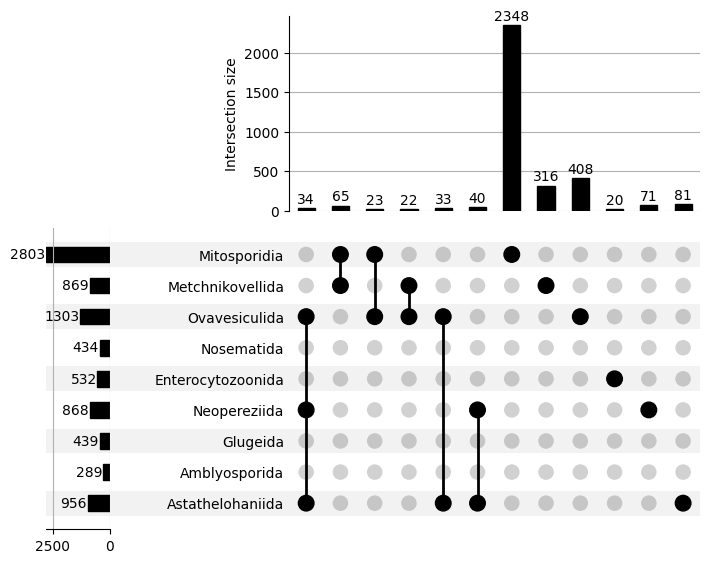

In [ ]:
# drawing upset plot that shows single copy genes found in every member of each group !!

import matplotlib.pyplot as plt
from upsetplot import UpSet, from_contents

plt.rcParams['svg.fonttype'] = 'none'

data_lists = {
    'Mitosporidia': Mitosporidia_core,
    'Metchnikovellida': Metchnikovellida_core,
    'Ovavesiculida': Ovavesiculida_core,
    'Nosematida': Nosematida_core,
    'Enterocytozoonida': Enterocytozoonida_core,
    'Neopereziida': Neopereziida_core,
    'Glugeida': Glugeida_core,
    'Amblyosporida': Amblyosporida_core,
    'Astathelohaniida': OrphanLineage_core
}

upset_data = from_contents(data_lists)
upset_plot = UpSet(upset_data, show_counts=True, sort_categories_by='-input', min_subset_size=20, sort_by='-degree')
upset_plot.plot()
plt.show()

In [ ]:
# here i realised there is little conserved single copy gene sharing....

Mitosporidia_core = (set(Mitosporidia_core))
Metchnikovellida_core = (set(Metchnikovellida_core))
Ovavesiculida_core = (set(Ovavesiculida_core))
Neopereziida_core = (set(Neopereziida_core))
Nosematida_core = (set(Nosematida_core))
Enterocytozoonida_core = (set(Enterocytozoonida_core))
Glugeida_core = (set(Glugeida_core))
Amblyosporida_core = (set(Amblyosporida_core))
OrphanLineage_core = (set(OrphanLineage_core))

u = Ovavesiculida_core.intersection(Mitosporidia_core, Metchnikovellida_core, Nosematida_core, Enterocytozoonida_core, Neopereziida_core, Glugeida_core, Amblyosporida_core, OrphanLineage_core)
print(len(u))

f = Ovavesiculida_core.intersection(Nosematida_core, Enterocytozoonida_core, Neopereziida_core, Glugeida_core, Amblyosporida_core, OrphanLineage_core)
print(len(f))

3
12


In [ ]:
# what is the number of conserved single copy  genes per order

print("Mitosporidia:", len(Mitosporidia_core))
print("Metchnikovellida:", len(Metchnikovellida_core))
print("Ovavesiculida:", len(Ovavesiculida_core))
print("Orphan:", len(OrphanLineage_core))
print("Amblyosporida:", len(Amblyosporida_core))
print("Glugeida:", len(Glugeida_core))
print("Neopereziida:", len(Neopereziida_core))
print("Nosematida:", len(Nosematida_core))
print("Enterocytozoonida:", len(Enterocytozoonida_core))

Mitosporidia: 2803
Metchnikovellida: 869
Ovavesiculida: 1303
Orphan: 956
Amblyosporida: 289
Glugeida: 439
Neopereziida: 868
Nosematida: 434
Enterocytozoonida: 532


In [ ]:
# successive intersections to assess where the drop out of conserved single copy gene sharing occurs


u = set(Ovavesiculida_core)

for name, core in [
    ("Mitosporidia", Mitosporidia_core),
    ("Metchnikovellida", Metchnikovellida_core),
    ("Nosematida", Nosematida_core),
    ("Enterocytozoonida", Enterocytozoonida_core),
    ("Neopereziida", Neopereziida_core),
    ("Glugeida", Glugeida_core),
    ("Amblyosporida", Amblyosporida_core),
    ("OrphanLineage", OrphanLineage_core),
]:
    u &= set(core)
    print(f"{name:20s} {len(u)}")

Mitosporidia         322
Metchnikovellida     179
Nosematida           81
Enterocytozoonida    44
Neopereziida         35
Glugeida             15
Amblyosporida        4
OrphanLineage        3


In [ ]:
# successive intersections to assess where the drop out of conserved single copy gene sharing occurs
# excluding mitosporidia and metchnikovellida

u = set(Ovavesiculida_core)

for name, core in [
    ("Nosematida", Nosematida_core),
    ("Enterocytozoonida", Enterocytozoonida_core),
    ("Neopereziida", Neopereziida_core),
    ("Glugeida", Glugeida_core),
    ("Amblyosporida", Amblyosporida_core),
    ("OrphanLineage", OrphanLineage_core),
]:
    u &= set(core)
    print(f"{name:20s} {len(u)}")

Nosematida           317
Enterocytozoonida    171
Neopereziida         132
Glugeida             52
Amblyosporida        15
OrphanLineage        12


/software/treeoflife/conda/users/envs/team222/ak37/toytree/lib/python3.11/site-packages/upsetplot/data.py:385: FutureWarning: Downcasting object dtype arrays on .fillna, .ffill, .bfill is deprecated and will change in a future version. Call result.infer_objects(copy=False) instead. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  df.fillna(False, inplace=True)
/software/treeoflife/conda/users/envs/team222/ak37/toytree/lib/python3.11/site-packages/upsetplot/plotting.py:795: FutureWarning: A value is trying to be set on a copy of a DataFrame or Series through chained assignment using an inplace method.
The behavior will change in pandas 3.0. This inplace method will never work because the intermediate object on which we are setting values always behaves as a copy.

For example, when doing 'df[col].method(value, inplace=True)', try using 'df.method({col: value}, inplace=True)' or df[col] = df[col].method(value) instead, to perform the operation

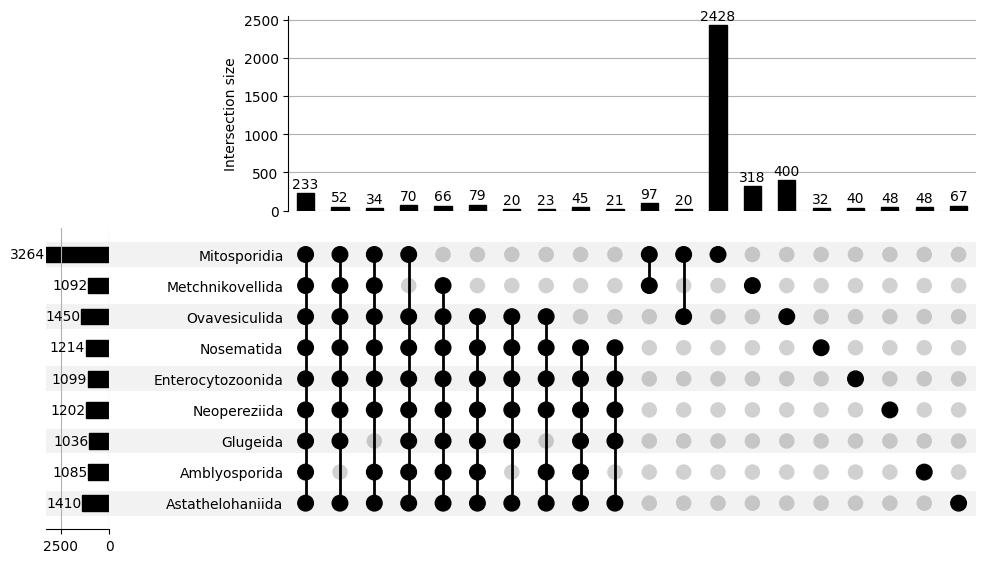

In [ ]:
# what would happen if I allowed up to four copies per genome (as long as distribution was  >=90% per order)

OrthogroupScores = {}
scoreFile = "orthogroup_TE_scores.txt"
with open(scoreFile) as file:
    for line in file:
        line = line.rstrip("\n")
        fields = line.split("\t")
        orthogroup = fields[0]
        score = float(fields[1])
        OrthogroupScores[orthogroup] = score

# Importing the orthofinder results
import pandas as pd
orthogroupsTSV = "Orthogroups.GeneCount.tsv"
df = pd.read_csv(orthogroupsTSV, sep='\t')

orthogroupDict = {} #Key is species, values is list of orthogroups
speciesList = []
with open(orthogroupsTSV) as file:
    for line in file:
        line = line.rstrip("\n")
        fields = line.split("\t")
        if fields[0] == "Orthogroup":
            speciesList = fields.copy()
        else:
            for i, field in enumerate(fields):
                if field.startswith("OG"):
                    orthogroup = field
                else:
                    if int(field) == 2 or int(field) == 1 or int(field) == 3 or int(field) == 4: 
                        ## only take single or double copy guys !!!
                        # retrieve position of field in list to find out what species it is
                        species = speciesList[i]
                        if species in orthogroupDict.keys() and OrthogroupScores[orthogroup] < 1:
                            orthogroupDict[species].append(orthogroup)
                        else:
                            if OrthogroupScores[orthogroup] < 1:
                                orthogroupDict[species] = [orthogroup]


from collections import defaultdict
from collections import Counter
import math

Ovavesiculida_core = []
Ovavesiculida_genomes_sets = []
numOfOvavesiculidaGenomes = 0
Ovavesiculida_genome_names = []
Ovavesiculida_file = "ovavesiculida_species_list.txt"
with open(Ovavesiculida_file) as f:
    for line in f:
        line = line.rstrip("\n")
        if line == "cjLepRept2":
            pass
        else:
            Ovavesiculida_genomes_sets.append(set(orthogroupDict[line]))
            numOfOvavesiculidaGenomes += 1
            Ovavesiculida_genome_names.append(line)

gene_counts = Counter()
for genome_set in Ovavesiculida_genomes_sets:
    gene_counts.update(genome_set)
threshold = math.ceil(numOfOvavesiculidaGenomes * 0.90)
Ovavesiculida_core = [gene for gene, count in gene_counts.items() if count >= threshold]

OrphanLineage_core = []
OrphanLineage_genomes_sets = []
numOfOrphanLineageGenomes = 0
OrphanLineage_genome_names = []
OrphanLineage_file = "astathelohaniida_species_list.txt"
with open(OrphanLineage_file) as f:
    for line in f:
        line = line.rstrip("\n")
        OrphanLineage_genomes_sets.append(set(orthogroupDict[line]))
        numOfOrphanLineageGenomes += 1
        OrphanLineage_genome_names.append(line)

gene_counts = Counter()
for genome_set in OrphanLineage_genomes_sets:
    gene_counts.update(genome_set)
threshold = math.ceil(numOfOrphanLineageGenomes * 0.90)
OrphanLineage_core = [gene for gene, count in gene_counts.items() if count >= threshold]

Amblyosporida_core = []
Amblyosporida_genomes_sets = []
numOfAmblyosporidaGenomes = 0
Amblyosporida_genome_names = []
Amblyosporida_file = "amblyosporida_species_list.txt"
with open(Amblyosporida_file) as f:
    for line in f:
        line = line.rstrip("\n")
        if line == "idAnoSqua2_b" or line == "ilAceEphe1_GCA_986199865.1" or line =="idMegDoli1_GCA_985805875.1" or line == "idLucSpea1_GCA_985809255.1":
            pass
        else:
            Amblyosporida_genomes_sets.append(set(orthogroupDict[line]))
            numOfAmblyosporidaGenomes += 1
            Amblyosporida_genome_names.append(line)

gene_counts = Counter()
for genome_set in Amblyosporida_genomes_sets:
    gene_counts.update(genome_set)
threshold = math.ceil(numOfAmblyosporidaGenomes * 0.90)
Amblyosporida_core = [gene for gene, count in gene_counts.items() if count >= threshold]

Glugeida_core = []
Glugeida_genomes_sets = []
numOfGlugeidaGenomes = 0
Glugeida_genome_names = []
Glugeida_file = "glugeida_species_list.txt"
with open(Glugeida_file) as f:
    for line in f:
        line = line.rstrip("\n")
        if line == "Dictyocoela_roeselum_GCA_016255985.1" or line == "Pseudoloma_neurophilia_GCA_001432165.1" or line == "Cucumispora_dikerogammari_GCA_014805705.1":
            pass
        else:
            Glugeida_genomes_sets.append(set(orthogroupDict[line]))
            numOfGlugeidaGenomes += 1
            Glugeida_genome_names.append(line)

gene_counts = Counter()
for genome_set in Glugeida_genomes_sets:
    gene_counts.update(genome_set)
threshold = math.ceil(numOfGlugeidaGenomes * 0.90)
Glugeida_core = [gene for gene, count in gene_counts.items() if count >= threshold]

Neopereziida_core = []
Neopereziida_genomes_sets = []
numOfNeopereziidaGenomes = 0
Neopereziida_genome_names = []
Neopereziida_file = "neopereziida_species_list.txt"
with open(Neopereziida_file) as f:
    for line in f:
        line = line.rstrip("\n")
        if line == "ieEphVulg1_GCA_985806015.1" or line == "idTipConf1_GCA_985805865.1":
            pass
        else:
            Neopereziida_genomes_sets.append(set(orthogroupDict[line]))
            numOfNeopereziidaGenomes += 1
            Neopereziida_genome_names.append(line)

gene_counts = Counter()
for genome_set in Neopereziida_genomes_sets:
    gene_counts.update(genome_set)
threshold = math.ceil(numOfNeopereziidaGenomes * 0.90)
Neopereziida_core = [gene for gene, count in gene_counts.items() if count >= threshold]


Nosematida_core = []
Nosematida_genomes_sets = []
numOfNosematidaGenomes = 0
Nosematida_genome_names = []
Nosematida_file = "nosematida_species_list.txt"
with open(Nosematida_file) as f:
    for line in f:
        line = line.rstrip("\n")
        if line == "ilMytImpu1_GCA_986195055.1" or line == "ihCicViri2_GCA_985805755.1" or line == "iyVulBima1_GCA_985801995.1" or line == "Nosema_muscidifuracis_GCA_028335825.1" or line == "iyGorLati1" or line == "ilBlaLact1_GCA_986194925.1" or line == "icChrPopu2" or line == "ilEreLige1_GCA_986264945.1" or line == "ilNocJanh1_GCA_986264975.1" or line == "iyForRufa2_GCA_985801395.1" or line == "Nosema_rusticus_GCA_046563365.1" or line == "iyAmbProt1_GCA_986191025.1" or line == "iySphCras2_GCA_985800635.1" or line == "iyNetVirg2_GCA_985803815.1" or line == "iyChoSubc1_GCA_986194725.1" or line == "ilOchDupl1_GCA_986194575.1":
            pass
        else:
            Nosematida_genomes_sets.append(set(orthogroupDict[line]))
            numOfNosematidaGenomes += 1
            Nosematida_genome_names.append(line)

gene_counts = Counter()
for genome_set in Nosematida_genomes_sets:
    gene_counts.update(genome_set)
threshold = math.ceil(numOfNosematidaGenomes * 0.90)
Nosematida_core = [gene for gene, count in gene_counts.items() if count >= threshold]

Enterocytozoonida_core = []
Enterocytozoonida_genomes_sets = []
numOfEnterocytozoonidaGenomes = 0
Enterocytozoonida_genome_names = []
Enterocytozoonida_file = "enterocytozoonida_species_list.txt"
with open(Enterocytozoonida_file) as f:
    for line in f:
        line = line.rstrip("\n")
        if line == "icHarAnxi1" or line == "Agmasoma_sp_GCA_029232285.1" or line == "Hepatospora_eriocheir_GCA_002087885.1" or line == "Enterocytozoon_hepatopenaei_GCA_026692725.1" or line == "Enterospora_canceri_GCA_002087915.1" or line == "Enterocytozoon_bieneusi_GCA_000209485.1" or line == "iqTelOcea3_a" or line == "iqTelOcea30" or line == "icAcuMacu1" or line == "ieEcdTorr1" or line == "cbUloPhyl1" or line == "idNeuQuad1_GCA_985805835.1" or line == "icBraCrep1" or line == "idAnoSqua2_a" or line == "idHydMili2_a" or line == "Alternosema_astaquatica_GCA_030386735.1":
            pass
        else:
            Enterocytozoonida_genomes_sets.append(set(orthogroupDict[line]))
            numOfEnterocytozoonidaGenomes += 1
            Enterocytozoonida_genome_names.append(line)

gene_counts = Counter()
for genome_set in Enterocytozoonida_genomes_sets:
    gene_counts.update(genome_set)
threshold = math.ceil(numOfEnterocytozoonidaGenomes * 0.90)
Enterocytozoonida_core = [gene for gene, count in gene_counts.items() if count >= threshold]


Mitosporidium = orthogroupDict["Mitosporidium_daphniae_GCA_052576055.1"]
qlDicSaun7 = orthogroupDict["qlDicSaun7"]
Mitosporidia_core = list(set(Mitosporidium).intersection(set(qlDicSaun7)))

Metchnikovella = orthogroupDict["Metchnikovella_incurvata_GCA_003600395.1"]
Amphiamblys = orthogroupDict["Amphiamblys_sp._WSBS2006_GCA_001875675.1"]
Metchnikovellida_core = list(set(Amphiamblys).intersection(set(Metchnikovella)))

Mitosporidia_core = list(set(Mitosporidia_core))
Metchnikovellida_core = list(set(Metchnikovellida_core))
Ovavesiculida_core = list(set(Ovavesiculida_core))
Neopereziida_core = list(set(Neopereziida_core))
Nosematida_core = list(set(Nosematida_core))
Enterocytozoonida_core = list(set(Enterocytozoonida_core))
Glugeida_core = list(set(Glugeida_core))
Amblyosporida_core = list(set(Amblyosporida_core))
OrphanLineage_core = list(set(OrphanLineage_core))


import matplotlib.pyplot as plt
from upsetplot import UpSet, from_contents

plt.rcParams['svg.fonttype'] = 'none'

data_lists = {
    'Mitosporidia': Mitosporidia_core,
    'Metchnikovellida': Metchnikovellida_core,
    'Ovavesiculida': Ovavesiculida_core,
    'Nosematida': Nosematida_core,
    'Enterocytozoonida': Enterocytozoonida_core,
    'Neopereziida': Neopereziida_core,
    'Glugeida': Glugeida_core,
    'Amblyosporida': Amblyosporida_core,
    'Astathelohaniida': OrphanLineage_core
}

upset_data = from_contents(data_lists)
upset_plot = UpSet(upset_data, show_counts=True, sort_categories_by='-input', min_subset_size=20, sort_by='-degree')
upset_plot.plot()
plt.show()

In [ ]:
# print those numbers out
# I also did the same analysis allowing only up to two, or up to three copies
Mitosporidia_core = (set(Mitosporidia_core))
Metchnikovellida_core = (set(Metchnikovellida_core))
Ovavesiculida_core = (set(Ovavesiculida_core))
Neopereziida_core = (set(Neopereziida_core))
Nosematida_core = (set(Nosematida_core))
Enterocytozoonida_core = (set(Enterocytozoonida_core))
Glugeida_core = (set(Glugeida_core))
Amblyosporida_core = (set(Amblyosporida_core))
OrphanLineage_core = (set(OrphanLineage_core))

u = Ovavesiculida_core.intersection(Mitosporidia_core, Metchnikovellida_core, Nosematida_core, Enterocytozoonida_core, Neopereziida_core, Glugeida_core, Amblyosporida_core, OrphanLineage_core)
print(len(u))

f = Ovavesiculida_core.intersection(Nosematida_core, Enterocytozoonida_core, Neopereziida_core, Glugeida_core, Amblyosporida_core, OrphanLineage_core)
print(len(f))

233
448
